<a href="https://colab.research.google.com/github/Arjunlearns/retail-sales-dashboard/blob/main/Sales_Analysis_UCI_Machine_Learning_Repository.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:

from google.colab import files

uploaded = files.upload()


Saving Online Retail.xlsx to Online Retail.xlsx


In [4]:

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:

print(df.shape)


(541909, 8)


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [8]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [9]:

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [10]:

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 5268


In [11]:

print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Negative prices:", (df["UnitPrice"] < 0).sum())
print("Zero prices:", (df["UnitPrice"] == 0).sum())


Negative quantities: 10624
Zero quantities: 0
Negative prices: 2
Zero prices: 2515


In [12]:

df_clean = df.copy()

print("Original rows:", len(df))
print("Working-copy rows:", len(df_clean))


Original rows: 541909
Working-copy rows: 541909


In [13]:

# TO Inspect the rows with negative prices
df_clean[df_clean["UnitPrice"] < 0]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [14]:

# Count invoices marked as cancellations
df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()


np.int64(9288)

In [15]:

# Start from a copy of the original dataset
df_clean = df.copy()

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Fill missing product descriptions
df_clean["Description"] = df_clean["Description"].fillna("Unknown")

# 3. Identify cancelled invoices
cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C")

# 4. Keep only valid positive-sales records
df_sales = df_clean[
    (~cancelled) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Rows in positive-sales analysis:", len(df_sales))
print("Missing descriptions:", df_sales["Description"].isnull().sum())
print("Missing customer IDs:", df_sales["CustomerID"].isnull().sum())


Original rows: 541909
Rows after removing duplicates: 536641
Rows in positive-sales analysis: 524878
Missing descriptions: 0
Missing customer IDs: 132186


In [16]:

print("Negative quantities remaining:", (df_sales["Quantity"] < 0).sum())
print("Non-positive prices remaining:", (df_sales["UnitPrice"] <= 0).sum())
print("Cancelled invoices remaining:",
      df_sales["InvoiceNo"].astype(str).str.startswith("C").sum())

df_sales.head()


Negative quantities remaining: 0
Non-positive prices remaining: 0
Cancelled invoices remaining: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [17]:

df_sales["Revenue"] = df_sales["Quantity"] * df_sales["UnitPrice"]

df_sales[["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]].head()


,InvoiceNo,Description,Quantity,UnitPrice,Revenue
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


In [18]:

total_revenue = df_sales["Revenue"].sum()
total_units = df_sales["Quantity"].sum()
total_invoices = df_sales["InvoiceNo"].nunique()
unique_products = df_sales["StockCode"].nunique()

print("Total positive sales revenue: £", round(total_revenue, 2))
print("Total units sold:", total_units)
print("Unique invoices:", total_invoices)
print("Unique products:", unique_products)


Total positive sales revenue: £ 10642110.8
Total units sold: 5572420
Unique invoices: 19960
Unique products: 3922


In [19]:

total_revenue = df_sales["Revenue"].sum()
total_units = df_sales["Quantity"].sum()
total_invoices = df_sales["InvoiceNo"].nunique()
unique_products = df_sales["StockCode"].nunique()

print("Total positive sales revenue: £", round(total_revenue, 2))
print("Total units sold:", total_units)
print("Unique invoices:", total_invoices)
print("Unique products:", unique_products)


Total positive sales revenue: £ 10642110.8
Total units sold: 5572420
Unique invoices: 19960
Unique products: 3922


In [20]:

# Convert invoice dates to datetime
df_sales["InvoiceDate"] = pd.to_datetime(df_sales["InvoiceDate"])

# Create a month column
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = df_sales.groupby("Month")["Revenue"].sum()

print(monthly_sales)


Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


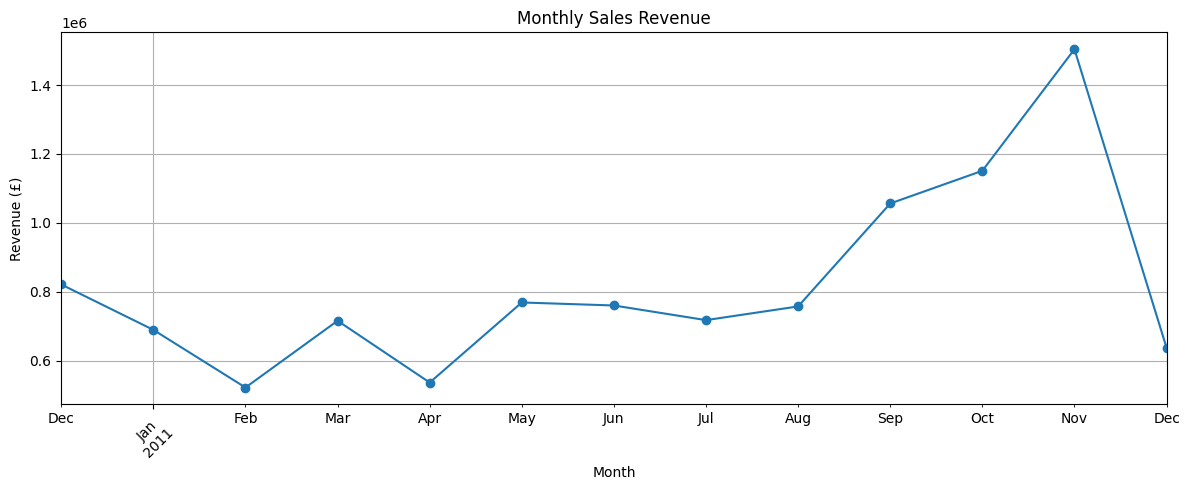

In [21]:

monthly_sales.plot(kind="line", marker="o", figsize=(12, 5))

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [22]:

top_products = (
    df_sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


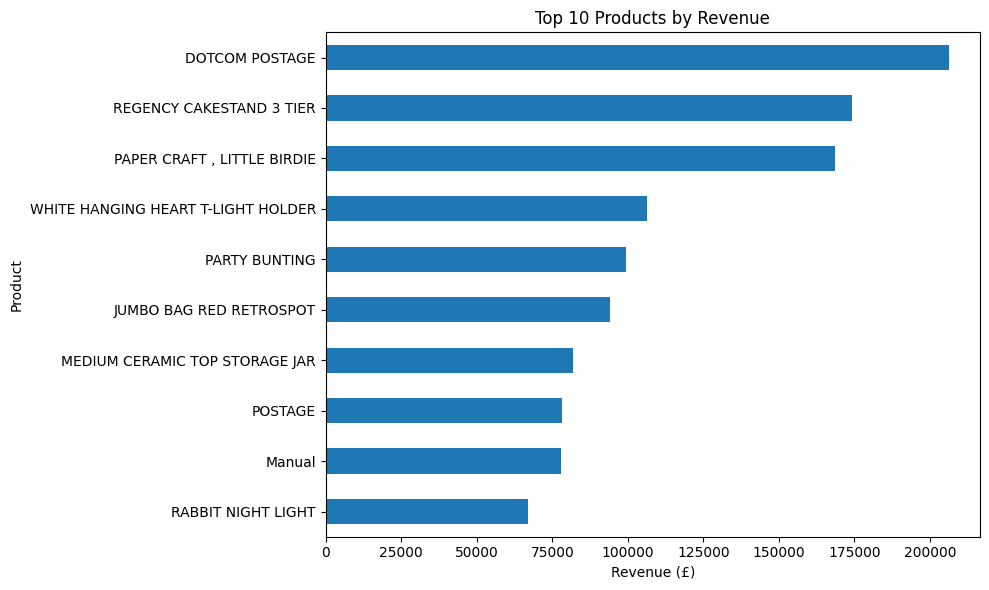

In [23]:

top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [24]:

country_sales = (
    df_sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_sales.head(10))


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


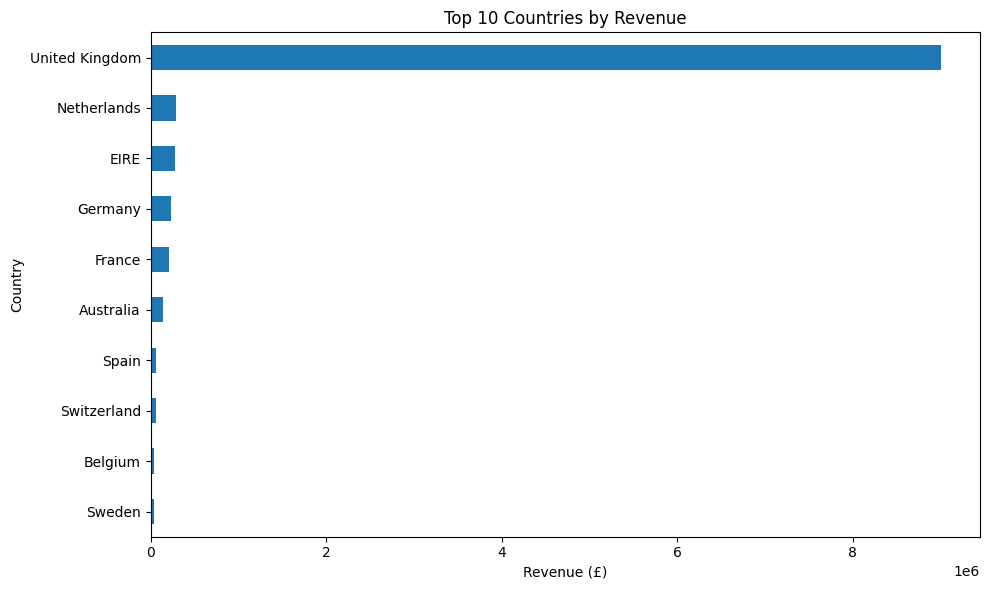

In [25]:

country_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [26]:

customer_sales = (
    df_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Number of identified customers:", len(customer_sales))
print("\nTop 10 customers by revenue:")
print(customer_sales.head(10))


Number of identified customers: 4338

Top 10 customers by revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


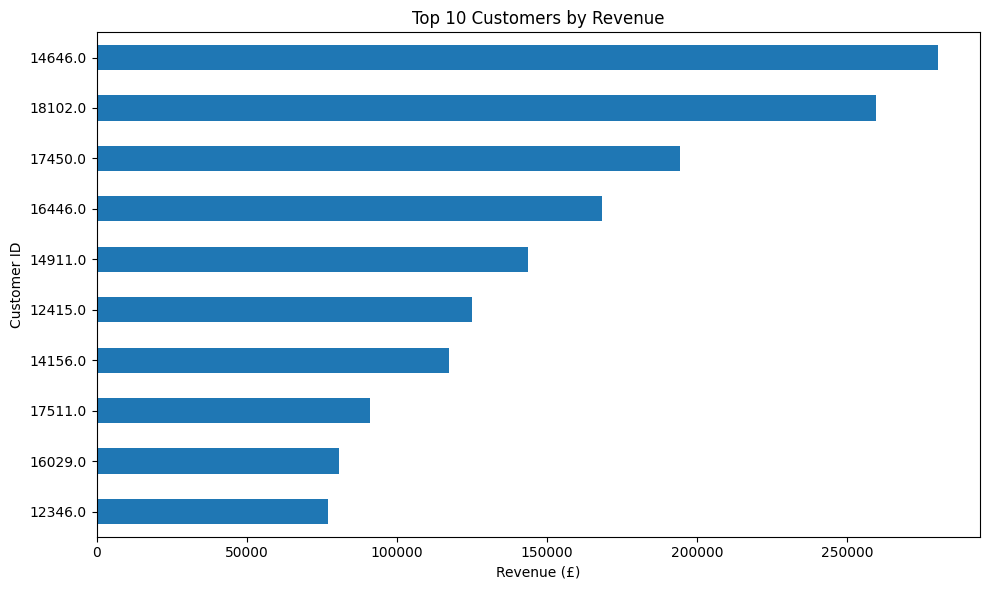

In [27]:

customer_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


In [28]:

# Overall sales KPIs
total_revenue = df_sales["Revenue"].sum()
total_units = df_sales["Quantity"].sum()
total_invoices = df_sales["InvoiceNo"].nunique()
unique_products = df_sales["StockCode"].nunique()
identified_customers = df_sales["CustomerID"].nunique()

# Best-performing categories
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

best_country = country_sales.idxmax()
best_country_revenue = country_sales.max()

best_product = top_products.idxmax()
best_product_revenue = top_products.max()

best_customer = customer_sales.idxmax()
best_customer_revenue = customer_sales.max()

print("PROJECT SUMMARY")
print("-" * 35)
print(f"Positive sales revenue: £{total_revenue:,.2f}")
print(f"Units sold: {total_units:,}")
print(f"Unique invoices: {total_invoices:,}")
print(f"Unique products: {unique_products:,}")
print(f"Identified customers: {identified_customers:,}")
print()
print(f"Best month: {best_month} (£{best_month_revenue:,.2f})")
print(f"Top country: {best_country} (£{best_country_revenue:,.2f})")
print(f"Top product description: {best_product} (£{best_product_revenue:,.2f})")
print(f"Top customer ID: {best_customer} (£{best_customer_revenue:,.2f})")


PROJECT SUMMARY
-----------------------------------
Positive sales revenue: £10,642,110.80
Units sold: 5,572,420
Unique invoices: 19,960
Unique products: 3,922
Identified customers: 4,338

Best month: 2011-11 (£1,503,866.78)
Top country: United Kingdom (£9,001,744.09)
Top product description: DOTCOM POSTAGE (£206,248.77)
Top customer ID: 14646.0 (£280,206.02)


In [30]:
df_sales.to_csv("retail_sales_cleaned.csv", index=False)

In [31]:
from google.colab import files
files.download("retail_sales_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>